In [134]:
# --- Orchestrator-Worker Workflow with Feedback + Tools ---
# Same as orchestrator_worker_with_feedback, but workers use web search tools
# (Tavily/DuckDuckGo) to ground their section output in external factual data.
from typing import Annotated, List, Literal, Optional, TypedDict,NotRequired
from pydantic import BaseModel, Field, field_validator, ValidationError
from operator import add
from langgraph.types import Send
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph, END, START
from langgraph.graph.state import CompiledStateGraph
from IPython.display import Image, display, Markdown
import re

# Google
from langchain_google_genai import ChatGoogleGenerativeAI

# HuggingFace
# from langchain_huggingface.embeddings import HuggingFaceEndpointEmbeddings
# from langchain_huggingface import ChatHuggingFace, HuggingFaceEndpoint

# Cohere
from langchain_cohere import CohereEmbeddings

# Prompts
from langchain.prompts import PromptTemplate
from langchain_core.messages import BaseMessage
from langchain_core.messages import SystemMessage, HumanMessage, ToolMessage, AIMessage
# tools
from langchain_core.tools import tool
from langchain_community.tools import DuckDuckGoSearchRun
from langchain_tavily import TavilySearch
import json

# Others
import os
from dotenv import load_dotenv
# # LangSmith
# import uuid
# from langchain_core.tracers.context import collect_runs
# from langchain_core.tracers.langchain import wait_for_all_tracers
# from langsmith import Client
# from langchain.callbacks.tracers import LangChainTracer

### **Orchestrator-Worker Agents: The Dynamic Version of Agents Parallelization**

In [135]:
from dotenv import load_dotenv

# Provide the filename as a string
load_dotenv('.env')

True

In [136]:
# loadding Google token
GOOGLE_API_KEY = os.getenv("GOOGLE_AI_STUDIO_GENERATIVE_MODEL_API_KEY")
# using Google from langchain
google_llm = ChatGoogleGenerativeAI(
    model="gemini-2.5-flash",
    temperature=0.1,
    max_output_tokens=4096,
    api_key=GOOGLE_API_KEY
)

In [137]:
# loading Google token
GOOGLE_API_KEY = os.getenv("GOOGLE_AI_STUDIO_GENERATIVE_MODEL_API_KEY")
# using Google from langchain
google_llm_3_7 = ChatGoogleGenerativeAI(
    model="gemini-3.7-flash",
    temperature=0.1,
    max_output_tokens=4096,
    api_key=GOOGLE_API_KEY
)

In [138]:
class Section(BaseModel):
    title: str = Field(..., description="Title of the section, e.g., 'Early Life', 'Major Achievements'.")
    description: str = Field(..., description="Brief overview of what should be covered in this section.")

In [139]:
class OutlinePlan(BaseModel):
    sections: List[Section] = Field(..., description="Dynamically planned sections for the scientist report.")

In [140]:
class ScientistInput(BaseModel):
    scientist: str = Field(min_length=3, max_length=100, description="The name of the scientist")

    @field_validator("scientist")
    def validate_scientist(cls, value):
        value = value.strip()
        if not re.search("[a-zA-Z]", value):
            raise ValueError("Scientist name must contain letters.")
        return value

In [141]:
class RefinedArticleOutput(BaseModel):
    refined_article: str = Field(description="Refined and synthesized final article under 1000 words.")

In [142]:
# Evaluator/Feedback/Critic
class EvaluatorCritic(BaseModel):
    status: Literal["ACCEPTED", "REJECTED"] = Field(
        description="Decide if the Refined Article is acceptable or not"

    )

    feedback: str = Field(
        description="Give a constructive reason why the article is not good enougn with points for improvement"
    )

In [143]:
# Structured LLMs 
planner_llm = google_llm.with_structured_output(OutlinePlan)
refined_article_llm = google_llm.with_structured_output(RefinedArticleOutput)

# Evaluator/Feedback/Critic
evaluator_llm = google_llm_3_7.with_structured_output(EvaluatorCritic)

## **Tool Definition**

In [144]:
# ================================================================
# Web Search Tool
# ================================================================

@tool
def web_search(query: str) -> str:
    """
    Searches the web for factual information regarding
    scientists, their history, and their achievements.

    Tavily is used as the external search provider.
    """

    try:

        # Create a Tavily search client.
        # max_results=1 keeps the amount of returned research small.
        search_tool = TavilySearch(
            max_results=1,
            topic="general",
            search_depth="basic",
            include_answer=True,
            include_raw_content=False,
        )

        # Execute the web search using the query supplied by Gemini.
        result = search_tool.invoke({
            "query": query
        })

        # Handle an empty response from Tavily.
        if not result:
            return "No search results were returned."

        # Store the useful parts of the search response.
        research_parts = []

        # ------------------------------------------------------------
        # Tavily's generated summary
        # ------------------------------------------------------------

        answer = result.get("answer")

        if answer:
            research_parts.append(
                f"SEARCH SUMMARY:\n{answer}"
            )

        # ------------------------------------------------------------
        # Individual search results
        # ------------------------------------------------------------

        results = result.get("results", [])

        for index, item in enumerate(results, start=1):

            title = item.get("title", "Untitled")
            url = item.get("url", "")
            content = item.get("content", "")

            research_parts.append(
                f"""
SOURCE {index}
Title: {title}
URL: {url}
Content:
{content}
""".strip()
            )

        # Handle a response that contains no usable information.
        if not research_parts:
            return "No useful external research was returned."

        # Combine the summary and source information into one string.
        return "\n\n".join(research_parts)

    except Exception as e:

        # Return the exception instead of hiding it.
        # This makes debugging the external search provider easier.
        return (
            f"WEB_SEARCH_ERROR: "
            f"{type(e).__name__}: {e}"
        )


# ================================================================
# Tool Registration
# ================================================================

# List of tools available to Gemini.
tools = [web_search]


# Create a lookup dictionary so Python can find a tool
# using the tool name returned by Gemini.
tools_by_name = {
    tool_obj.name: tool_obj
    for tool_obj in tools
}


# Bind the web_search tool to Gemini.
# Gemini can now decide when a web search is required.
llm_with_tools = google_llm.bind_tools(tools)

In [145]:
# example output of Tavily is 
# {'query': 'Stephen Hawking biography major scientific contributions', 'follow_up_questions': None, 'answer': "Stephen Hawking made major contributions to general relativity, including theorems on singularities and the prediction of Hawking radiation from black holes. His work on black holes and cosmology advanced understanding of the universe's origins and structure.", 'images': [], 'results': [{'url': 'https://en.wikipedia.org/wiki/Stephen_Hawking', 'title': 'Stephen Hawking', 'content': '> Hawking has made major contributions to the field of general relativity. These derive from a deep understanding of what is relevant to physics and astronomy, and especially from a mastery of wholly new mathematical techniques. Following the pioneering work of Penrose he established, partly alone and partly in collaboration with Penrose, a series of successively stronger theorems establishing the fundamental result that all realistic cosmological models must possess singularities. Using [...] Hawking\'s scientific works included a collaboration with Roger Penrose on gravitational singularity theorems in the framework of general relativity, and the theoretical prediction that black holes emit radiation, often called Hawking radiation. Initially, Hawking radiation was controversial. By the late 1970s, and following the publication of further research, the discovery was widely accepted as a major breakthrough in theoretical physics. Hawking was the first to set out a theory of cosmology [...] "Great Debates (international relations)") (1980s)  Science wars (1990s) | | Contributions |  The Course in Positive Philosophy (1830)  A General View of Positivism (1848)  Critical History of Philosophy (1869)  Idealism and Positivism (1879–1884)  The Analysis of Sensations (1886)  The Logic of Modern Physics (1927)  Language, Truth, and Logic (1936)  The Two Cultures (1959)  The Universe in a Nutshell (2001) | | Proponents |  Richard Avenarius  A. J. Ayer  Berlin Circle / Vienna Circle', 'score': 0.9721515, 'raw_content': None, 'id': 'b3985c-00'}], 'response_time': 0.0, 'request_id': '95d216c1-fcf8-4444-bc11-3746591db2aa'}

## **Inline Research Helper Function for Tools**

In [146]:
# Research Helper 

def perform_research_with_tools(query_prompt: str) -> str:
    """
    Allows Gemini to decide whether web_search should be used.

    Flow:

        Research request
                ↓
        Gemini + bound web_search tool
                ↓
        Gemini requests web_search
                ↓
        Python executes Tavily
                ↓
        Tavily returns search results
                ↓
        Results are returned to the calling graph node

    IMPORTANT:

    I deliberately do NOT send Gemini's original AIMessage
    containing tool-call metadata back to Gemini.

    This avoids the compatibility/serialization problem that
    can produce:

        'int' object has no attribute 'name'
    """

    # ------------------------------------------------------------
    # Build the initial conversation for Gemini.
    # ------------------------------------------------------------

    messages = [
        SystemMessage(
            content=(
        "You are a research assistant. "
        "Decide whether web_search is necessary to answer "
        "the user's request accurately. "
        "Use web_search when external factual information "
        "is needed or would materially improve accuracy. "
        "If web search is not necessary, answer directly."
            )
        ),
        HumanMessage(content=query_prompt),
    ]

    try:

        # ========================================================
        # 1. ASK GEMINI WHETHER A TOOL SHOULD BE USED
        # ========================================================

        # Gemini receives the request together with the available
        # web_search tool and decides whether to call it.
        response = llm_with_tools.invoke(messages)

        # LangChain exposes Gemini's requested tools through
        # the tool_calls attribute.
        tool_calls = getattr(response, "tool_calls", None)


        # ========================================================
        # 2. GEMINI DID NOT REQUEST A TOOL
        # ========================================================

        if not tool_calls:

            # If Gemini decided that no web search is necessary,
            # return its response directly.
            return str(response.content)


        # ========================================================
        # 3. EXECUTE GEMINI'S TOOL CALLS
        # ========================================================

        # Store the results returned by each requested tool.
        research_results = []

        for tool_call in tool_calls:

            # Gemini/LangChain normally returns tool calls as
            # dictionaries. Ignore anything unexpected.
            if not isinstance(tool_call, dict):
                continue


            # ----------------------------------------------------
            # Get the requested tool name
            # ----------------------------------------------------

            tool_name = tool_call.get("name")

            if not tool_name:
                continue


            # ----------------------------------------------------
            # Find the corresponding Python tool
            # ----------------------------------------------------

            tool_obj = tools_by_name.get(tool_name)

            if tool_obj is None:

                research_results.append(
                    f"Unknown tool requested: {tool_name}"
                )

                continue


            # ----------------------------------------------------
            # Extract the arguments Gemini supplied
            # ----------------------------------------------------

            tool_args = tool_call.get("args", {})

            if tool_args is None:
                tool_args = {}


            # Gemini normally returns arguments in this format:
            #
            # {
            #     "query": "Stephen Hawking biography..."
            # }
            #
            # Convert unexpected string arguments into a dictionary.

            if isinstance(tool_args, str):

                try:

                    tool_args = json.loads(tool_args)

                except json.JSONDecodeError:

                    # If the string is not JSON, treat the entire
                    # string as the search query.
                    tool_args = {
                        "query": tool_args
                    }


            # If Gemini returns another unexpected argument type,
            # convert it into a valid query dictionary.
            if not isinstance(tool_args, dict):

                tool_args = {
                    "query": str(tool_args)
                }


            # ----------------------------------------------------
            # Safety fallback for a missing query
            # ----------------------------------------------------

            # If Gemini fails to provide a search query, use the
            # original research request instead.
            if not tool_args.get("query"):

                tool_args["query"] = query_prompt


            # ====================================================
            # 4. EXECUTE THE SELECTED TOOL
            # ====================================================

            try:

                # This executes the Tavily web search.
                observation = tool_obj.invoke(tool_args)

                # Store the returned research if anything was found.
                if observation:

                    research_results.append(
                        str(observation)
                    )

            except Exception as e:

                # Preserve the error in the research output so that
                # the calling node can see that the search failed.
                research_results.append(
                    f"WEB_SEARCH_ERROR: "
                    f"{type(e).__name__}: {e}"
                )


        # ========================================================
        # 5. RETURN THE RESEARCH TO THE GRAPH NODE
        # ========================================================

        if research_results:

            # Combine results from all requested tool calls.
            return "\n\n".join(research_results)

        # Gemini requested a tool, but no useful result was produced.
        return "No useful external research was returned."


    except Exception as e:

        # This catches failures occurring during Gemini's
        # tool-selection stage rather than inside Tavily itself.
        print(
            f"Research tool-selection failed: "
            f"{type(e).__name__}: {e}"
        )

        return (
            f"Research unavailable: "
            f"{type(e).__name__}: {e}"
        )

In [147]:
# Shared Main Graph State: Orchestrator State
class State(TypedDict):
    input: str
    scientist: NotRequired[str]
    sections: NotRequired[List[Section]]
    # Key reducer operator.add allows parallel workers to append outputs safetly
    completed_sections: Annotated[List[str], add] # expects a list of strings
    article: NotRequired[str]
    refined_article: NotRequired[str]

    # EvaluatorCritic
    feedback: NotRequired[str]
    accepted_rejected: NotRequired[str]
    feedback_count: NotRequired[int] # Crucial: Persist loop count in state

In [148]:
# Individual Worker State
class WorkerState(TypedDict):
    scientist: str
    section: Section

In [149]:
# Extracts the scientist's name from the user input via LLM
def scientist_name_extraction(state:State):
    # Extract the scientist's name from the input
    prompt = PromptTemplate.from_template(
    """Extract the scientist's name from the input provided by the user. 
    The input is: {input}.
    """
    )

    extraction_data  = {"input": state["input"]}
    extraction_chain  = prompt | google_llm
    response = extraction_chain.invoke(extraction_data)

    try:
        validated = ScientistInput.model_validate(
                    {
                    "scientist": response.content.strip()
                    }
        )
        # Assuming the response contains the extracted name in a field called 'content'
        return {"scientist": validated.scientist}

    except ValidationError as e:
        print(e.errors()[0]["msg"])

In [150]:
# Dynamically plans article sections using structured LLM output
def orchestrator(state: State):
    """
    Orchestrator: Dynamically breaks down the topic into 3-5 key sections
    tailored to the specific scientist (e.g. Early Life, Theories, Impact).
    """
    plan = planner_llm.invoke([
        SystemMessage(content="""You are an expert editor. Create an outline plan of distinct sections for an article about the given scientist.
        Which covers the history and the achievements of the scientist
        """),
        HumanMessage(content=f"Scientist: {state['scientist']}")
    ])

    # Initialise state fields
    return {
        "sections": plan.sections,
        "completed_sections": []
    }

In [151]:
def worker_section_writer(state: WorkerState):
    """
    Worker: Executes a single section task generated by the orchestrator.
    Executes in parallel per section via Send API.
    """
    scientist = state["scientist"]
    title = state["section"].title
    description = state["section"].description
    
    research_prompt = f"""
    Research the following section for an article
    about {scientist}.

    Section title:
    {title}

    Section focus:
    {description}

    Find accurate factual information relevant
    specifically to this section.

    Prioritize:
    - dates
    - scientific discoveries
    - important publications
    - collaborations
    - awards
    - historical facts
    - scientific impact

    Avoid irrelevant information.
    """
    research_data = perform_research_with_tools(
        research_prompt
    )

    print(
        f"\n--- RESEARCH: {title} ---"
    )

    print(research_data)

    print(
        f"--- END RESEARCH ---\n"
    )
    prompt = PromptTemplate.from_template(
        """Write a comprehensive section for an article about {scientist}.
        Section Title: {title}
        Section Focus: {description}
        External research:{research}
       
        Requirements:

        - Use the research where relevant.
        - Prioritize factual accuracy.
        - Do not invent facts.
        - Do not mention the research process.
        - Do not mention Tavily.
        - Do not mention tools.
        - Write clear Markdown.
        - Write only this section.
        - Do not add an introduction or intros.
        """
    )
    
    chain = prompt | google_llm
    response = chain.invoke({
        "scientist": scientist,
        "title": title,
        "description": description,
        "research": research_data
    })
    content = str(response.content).strip()
    formatted_section = f"### {title}\n\n{content}"
    
    # Reducer appends this entry into state["completed_sections"]
    return {"completed_sections": [formatted_section]}

In [152]:
# Merges all worker-written sections into a single article, optionally refining if >1000 words
def synthesizer(state: State):
    """
    Synthesizer: Takes all completed section outputs from parallel workers,
    combines them, and applies word-length checks before optionally refining.
    """
    completed_sections = state.get("completed_sections", [])
    current_count = state.get("feedback_count", 0)
    
    # 1. Guard check: Ensure worker outputs exist
    if not completed_sections:
        print("WARNING: No completed sections were produced.")
        return {
            "article": "",
            "refined_article": "Error: Article was not generated properly."
        }

    # 2. Combine section outputs into full draft
    generated_article = "\n\n".join(sec.strip() for sec in completed_sections if sec and sec.strip())
    article_length = len(generated_article.split())

    # 3. Branching logic based on word count
    if article_length > 1000:
        print("Article contains {0} words.\nNow refining!".format(article_length))
        prompt = PromptTemplate.from_template(
            """Summarise the following article about {scientist} in less than 1000 words from given article\n{article}.\n
          Requirements:
        - Preserve the most important factual information.
        - Preserve important dates.
        - Preserve major scientific discoveries.
        - Preserve important collaborations.
        - Preserve important publications.
        - Preserve major awards where relevant.
        - Remove repetition.
        - Remove unnecessary wording.
        - Do not invent facts.
        - Do not mention the editing process.
        - Do not mention Tavily.
        - Do not mention tools.
        - Do not mention this prompt.
        - Keep the article factually accurate.
        - Keep clear section headings.
        - The final article MUST contain fewer than 1000 words. 
        Final Article must be in Markdown format with different sections. For example;
        ## **Title**

        ### **History**

        ### **Achievements**

        ### **Main Contributions**
        
        ## **Conclusion**

        This is just an example you can modify
        
        You must give the article in Markdown format
            """
        )
        refined_article_data = {
            "scientist": state["scientist"], 
            "article": generated_article
        }
        refined_article_chain = prompt | refined_article_llm
        try:
            response = refined_article_chain.invoke(refined_article_data)

            # Null check to prevent 'NoneType' object has no attribute 'refined_article'
            if response and hasattr(response, "refined_article") and response.refined_article:
                refined_text = response.refined_article
            else:
                print("Warning: Structured output returned None. Falling back to generated draft.")
                refined_text = generated_article
        except Exception as e:
            print(
                f"WARNING: Article refinement failed: "
                f"{type(e).__name__}: {e}"
            )

        refined_text = generated_article
        return {
            "article": generated_article,
            "refined_article": refined_text,
            "feedback_count": current_count        
        }
        
    else:
        print("Initial article is already under 1000 words. No refinement needed.")
        return {
            "article": generated_article,
            "refined_article": generated_article,
            "feedback_count": current_count        
        }

In [153]:
# Uses Send API to spawn parallel worker nodes, one per planned section
def assign_workers(state: State):
    """
    Conditional edge function that uses Send API to dynamically 
    spawn 'worker_section_writer' nodes for every planned section.
    """
    return [
        Send(
            "worker_section_writer", 
            {
                "scientist": state["scientist"], 
                "section": section
            }
        ) 
        for section in state["sections"]
    ]

In [154]:
# Revises the article using evaluator feedback; increments feedback_count
def refine_article_with_feedback(state: State):
    generated_article = state.get("article", "")
    current_count = state.get("feedback_count", 0)
    # Ensure a fallback to generated_article if refined_article is empty string ""
    existing_refined = state.get("refined_article") or generated_article
    feedback_prompt = PromptTemplate.from_template(
        """Improve the refined article\n{refined_article}.\nWith the provided feedback \n{feedback}
        You must give the article in Markdown format.
        """
    )
    feedback_data = {
        "refined_article": existing_refined,
        "feedback": state["feedback"]
    }
    
    feedback_chain = feedback_prompt | refined_article_llm
    response = feedback_chain.invoke(feedback_data)
    
    refined_text = response.refined_article if (response and response.refined_article) else existing_refined
    current_count+=1
    print(f"Article was rejected {current_count} time(s)!")
    return {
        "refined_article": refined_text,
        "feedback_count": current_count 
    }

In [155]:
# LLM critic evaluates the refined article and returns ACCEPTED/REJECTED with feedback
def llm_evaluator(state: State):
    """Evaluation of Articles"""
    refined_text = state.get("refined_article", state.get("article", ""))
    try:
        critic = evaluator_llm.invoke([
            SystemMessage(content="You are an expert critic. Evaluate the provided article."),
            HumanMessage(content=f"Article:\n{refined_text}")
        ])
        status = critic.status if (critic and hasattr(critic, "status")) else "REJECTED"
        feedback = critic.feedback if (critic and hasattr(critic, "feedback")) else "Evaluation error."
    except Exception as e:
        status = "REJECTED"
        feedback = f"Error: {str(e)}"

    return {"accepted_rejected": status, "feedback": feedback}

In [156]:
# Returns ACCEPTED if max retries (3) reached, otherwise passes through evaluator verdict
MAX_FEEDBACK_RETRIES = 3
def route_feedback(state:State):
    """Route the refined article or end based upon the feedback from the evaluator"""
    if state.get("feedback_count", 0) >= MAX_FEEDBACK_RETRIES:
        print(
            f"Maximum feedback retries "
            f"({MAX_FEEDBACK_RETRIES}) reached."
        )
        return "ACCEPTED"
    return state.get("accepted_rejected", "ACCEPTED")

In [157]:
# Assembles the full graph: extraction -> orchestrator -> Send() -> workers -> synthesizer -> feedback loop
def build_orchestrator_worker_graph():
    workflow = StateGraph(State)

    # Add Nodes
    workflow.add_node("scientist_name_extraction", scientist_name_extraction)
    workflow.add_node("orchestrator",orchestrator)
    workflow.add_node("worker_section_writer", worker_section_writer)
    workflow.add_node("synthesizer", synthesizer)
    workflow.add_node("refine_article_with_feedback", refine_article_with_feedback)  # NEW NODE
    workflow.add_node("evaluate_feedback_llm",llm_evaluator)

    # Static Edges
    workflow.add_edge(START, "scientist_name_extraction")
    workflow.add_edge("scientist_name_extraction","orchestrator")

    # Orchestrator --> Dynamic Parallel Workers via Send()
    workflow.add_conditional_edges(
        "orchestrator",
        assign_workers,
        ["worker_section_writer"]
    )

    # Workers --> Synthesizer --> END
    workflow.add_edge("worker_section_writer","synthesizer")
    
    # Feeback Route
    workflow.add_edge("synthesizer", "evaluate_feedback_llm")

    # adding the evaluation path
    workflow.add_edge("refine_article_with_feedback", "evaluate_feedback_llm")
    workflow.add_conditional_edges(
        "evaluate_feedback_llm",
        route_feedback,
        {
            "ACCEPTED": END,
            "REJECTED": "refine_article_with_feedback" # Routes directly to feedback node
        }
    )


    return workflow.compile()

In [158]:
graph = build_orchestrator_worker_graph()

In [159]:
# Renders the LangGraph workflow as a Mermaid diagram
def graph_visualiser(graph):
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception as e:
        print(e)

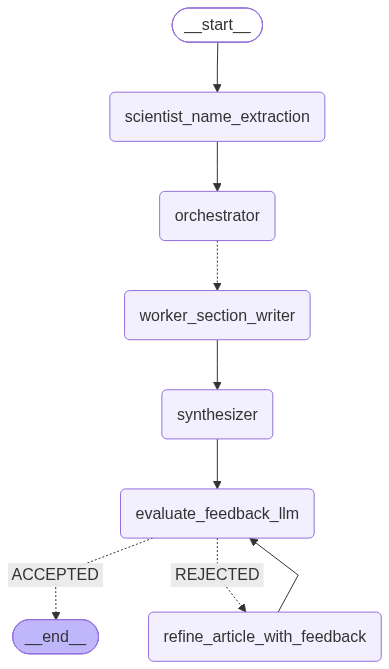

In [160]:
graph_visualiser(graph)

In [161]:
results = graph.invoke({
    "input": "Write an in-depth article about Stephen William Hawking"
    # "input": "Write an in-depth article about Marie Curie"
})


--- RESEARCH: The Onset of Illness and Early Research ---
SEARCH SUMMARY:
Stephen Hawking was diagnosed with ALS in 1963 at age 21. He continued his studies in cosmology and relativity, obtaining his PhD in 1966. His condition was initially slow-progressing.

SOURCE 1
Title: Stephen Hawking
URL: https://en.wikipedia.org/wiki/Stephen_Hawking
Content:
Hawking's first year as a doctoral student was difficult. He was initially disappointed to find that he had been assigned Dennis William Sciama, one of the founders of modern cosmology, as a supervisor rather than the noted astronomer Fred Hoyle, and he found his training in mathematics inadequate for work in general relativity and cosmology. After being diagnosed with motor neurone disease, Hawking fell into a depression. Although his doctors advised that he continue with his studies, he felt [...] Hawking was born in Oxford into a family of physicians. In 1959, at the age of 17, he began his university education at University College, Ox

In [162]:
# Formats and displays all state fields using IPython Markdown rendering
def results_formatting(results:dict):
    """The Results formatter"""
    for key,value in results.items():
        if isinstance(value, str):
            print(f"{key.upper()}")
            display(Markdown(value.strip()))
        elif isinstance(value, list):
            print(f"{key.upper()}\nFirst Value in the list is\n{value[0]}\n")
        else:
            print(f"{key.upper()}\n{value}\n")

In [163]:
results

{'input': 'Write an in-depth article about Stephen William Hawking',
 'scientist': 'Stephen William Hawking',
 'sections': [Section(title='Introduction', description="An overview of Stephen Hawking's life and his profound impact on science and the public."),
  Section(title='Early Life and Education', description='Details of his birth, childhood, and academic journey through Oxford and Cambridge.'),
  Section(title='The Onset of Illness and Early Research', description='Discussion of his ALS diagnosis and the beginning of his groundbreaking work in cosmology.'),
  Section(title='Major Scientific Contributions', description='Exploration of his key theories and discoveries, including black holes, singularities, and Hawking radiation.'),
  Section(title='Popularizing Science and Public Recognition', description='His efforts to communicate complex scientific ideas to a broad audience through books and media appearances.'),
  Section(title='Later Life, Challenges, and Continued Work', descr

In [164]:
sections_total = 0
for section_num in range(len(results['sections'])):
    sections_total += 1

print(f"Total Sections/Workers present are: {sections_total}")

Total Sections/Workers present are: 7


In [165]:
results_formatting(results)

INPUT


Write an in-depth article about Stephen William Hawking

SCIENTIST


Stephen William Hawking

SECTIONS
First Value in the list is
title='Introduction' description="An overview of Stephen Hawking's life and his profound impact on science and the public."

COMPLETED_SECTIONS
First Value in the list is
### Introduction

### Introduction

Stephen William Hawking (8 January 1942 – 14 March 2018) was an English theoretical physicist, cosmologist, and author whose groundbreaking work profoundly reshaped our understanding of the universe. A towering figure in modern science, Hawking held the prestigious Lucasian Professorship of Mathematics at the University of Cambridge from 1979 to 2009, a post once held by Isaac Newton. He also served as the director of research at the Centre for Theoretical Cosmology at Cambridge, dedicating his life to unraveling the mysteries of space, time, and gravity.

Hawking's most significant scientific contributions centered on black holes and relativity. He is widely celebrated for his theories on the nature of black holes, including the concept of Hawkin

...

FEEDBACK


The article is well-structured, comprehensive, and factually accurate. It effectively balances biographical narrative with lucid explanations of Hawking's scientific achievements (singularity theorems, Hawking radiation, Hartle-Hawking state) and his broader cultural impact. The tone is engaging, formal, and objective throughout.

ACCEPTED_REJECTED


ACCEPTED

FEEDBACK_COUNT
1



In [166]:
results = graph.invoke({
    # "input": "Write an in-depth article about Stephen William Hawking"
    "input": "Write an in-depth article about Marie Curie"
})


--- RESEARCH: Scientific Beginnings and Partnership with Pierre Curie ---
SEARCH SUMMARY:
Marie Curie married Pierre Curie in 1895. They collaborated on research leading to the discovery of radioactivity and the elements polonium and radium in 1898. They shared the Nobel Prize in Physics in 1903.

SOURCE 1
Title: December 1898: The Curies Discover Radium
URL: https://www.aps.org/apsnews/2004/12/curies-1898-discover-radium
Content:
APS News | This Month in Physics History

# December 1898: The Curies Discover Radium

Dec. 1, 2004

Women physicists were a rarity in the 19th century, but even rarer were husband-and-wife collaborative teams. Pierre and Marie Curie made history not only in that respect, but also because their scientific teamwork led to the discovery of radioactivity and two new elements in the periodic table, for which they shared the Nobel Prize in Physics.
--- END RESEARCH ---


--- RESEARCH: Early Life and Education ---
SEARCH SUMMARY:
Marie Curie was born in Warsaw in 

In [167]:
sections_total = 0
for section_num in range(len(results['sections'])):
    sections_total += 1

print(f"Total Sections/Workers present are: {sections_total}")

Total Sections/Workers present are: 9


In [168]:
results_formatting(results)

INPUT


Write an in-depth article about Marie Curie

SCIENTIST


Marie Curie

SECTIONS
First Value in the list is
title='Introduction' description="Brief overview of Marie Curie's life and her significance as a pioneering scientist."

COMPLETED_SECTIONS
First Value in the list is
### Introduction

## Introduction

Marie Curie, born Maria Skłodowska, stands as one of history's most influential and pioneering scientists. Her groundbreaking work in radioactivity not only revolutionized physics and chemistry but also laid foundations for new medical treatments. Curie's relentless dedication led to the discovery of two new elements, polonium and radium, with her isolating radium as radium chloride in 1902 and determining its atomic weight.

Her extraordinary contributions were recognized with two Nobel Prizes, making her a figure of unparalleled achievement. In 1903, she, along with her husband Pierre Curie and Henri Becquerel, was awarded the Nobel Prize in Physics for their joint research on radioactivity. This made her the first woman ever to receive a Nobel Prize

...

FEEDBACK


The article is comprehensive, well-structured, and historically accurate. It effectively balances Marie Curie's scientific discoveries, academic milestones, humanitarian contributions during WWI, and personal resilience. For minor future refinements, consider briefly mentioning the 'Flying University' (Uniwersytet Latający) in Poland during her early education and noting her cause of death (aplastic anemia resulting from long-term radiation exposure) in the Later Life section to underscore the personal cost of her scientific devotion. Overall, the article is of high quality and ready for publication.

ACCEPTED_REJECTED


ACCEPTED

FEEDBACK_COUNT
2

